In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("All libraries imported successfully!")

ModuleNotFoundError: No module named 'pandas'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/loan_data.csv")

print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '../data/loan_data.csv'

In [2]:
import os

print("Current Location:", os.getcwd())

print("\nAvailable Files:")
print(os.listdir())

Current Location: c:\Users\ADMIN\Desktop\weekly task\week 2 Assessment\notebooks

Available Files:
['task1.ipynb']


In [3]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load dataset
data = load_breast_cancer()

# Convert into DataFrame
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)


df["target"] = data.target

print(df.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nTarget Distribution:")
print(df["target"].value_counts())

Dataset Shape: (569, 31)

Columns:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Missing Values:
0

Target Distribution:
target
1    357
0    212
Name: count, dtype: int64


In [5]:


X = df.drop("target", axis=1)

y = df["target"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (569, 30)
y Shape: (569,)


In [6]:
from sklearn.model_selection import train_test_split



X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Temporary Data:", X_temp.shape)

Training Data: (341, 30)
Temporary Data: (228, 30)


In [7]:


X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (341, 30)
Validation: (114, 30)
Test: (114, 30)


In [8]:
print("Train distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

Train distribution:
target
1    0.627566
0    0.372434
Name: proportion, dtype: float64

Validation distribution:
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64

Test distribution:
target
1    0.622807
0    0.377193
Name: proportion, dtype: float64


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

depths = [1, 3, 5, 10, None]

train_scores = []
val_scores = []

In [13]:
for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

   
    model.fit(X_train, y_train)

    
    train_pred = model.predict(X_train)

    
    val_pred = model.predict(X_val)

   
    train_acc = accuracy_score(y_train, train_pred)

    val_acc = accuracy_score(y_val, val_pred)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(
        f"Depth {depth}: "
        f"Train Accuracy = {train_acc:.2f}, "
        f"Validation Accuracy = {val_acc:.2f}"
    )

Depth 1: Train Accuracy = 0.93, Validation Accuracy = 0.94
Depth 3: Train Accuracy = 0.97, Validation Accuracy = 0.96
Depth 5: Train Accuracy = 0.99, Validation Accuracy = 0.96
Depth 10: Train Accuracy = 1.00, Validation Accuracy = 0.96
Depth None: Train Accuracy = 1.00, Validation Accuracy = 0.96


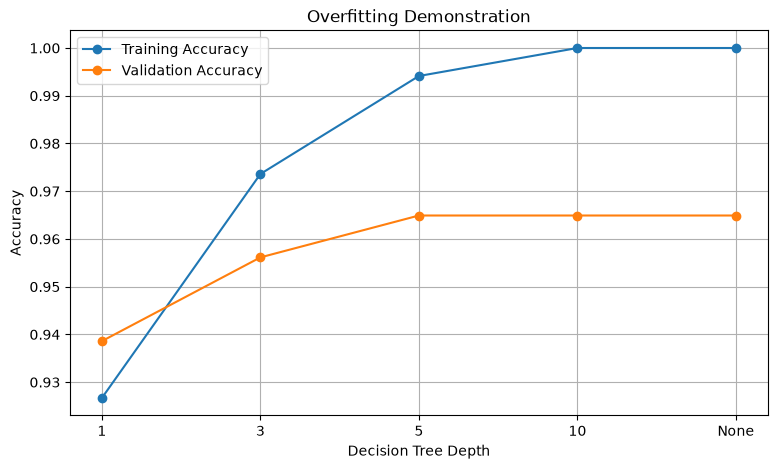

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(
    ["1", "3", "5", "10", "None"],
    train_scores,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    ["1", "3", "5", "10", "None"],
    val_scores,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Decision Tree Depth")
plt.ylabel("Accuracy")

plt.title("Overfitting Demonstration")

plt.legend()
plt.grid()

plt.show()

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [16]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

In [17]:
scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Individual Scores:", scores)

print("Mean Accuracy:", scores.mean())

print("Standard Deviation:", scores.std())

Individual Scores: [0.95652174 0.97058824 0.95588235 0.97058824 0.98529412]
Mean Accuracy: 0.9677749360613811
Standard Deviation: 0.010870317410410951


observation:

Cross-validation divides the training dataset into five folds. Four folds are used for training and one fold is used for validation. This process repeats five times. Mean accuracy measures the average model performance, while standard deviation measures the variation in performance across folds.

In [18]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler_bad = StandardScaler()

# Incorrect: Fit scaler on complete dataset
X_scaled_bad = scaler_bad.fit_transform(X)

# Now split the scaled data
X_train_bad, X_temp_bad, y_train_bad, y_temp_bad = train_test_split(
    X_scaled_bad,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

print("Incorrect Scaling Completed")

Incorrect Scaling Completed


In [19]:
# Create scaler
scaler_good = StandardScaler()

# Fit only on training data
X_train_scaled = scaler_good.fit_transform(X_train)

# Transform validation data
X_val_scaled = scaler_good.transform(X_val)

# Transform test data
X_test_scaled = scaler_good.transform(X_test)

print("Correct Scaling Completed")

Correct Scaling Completed


In [20]:
print("Incorrect Scaling:")
print("Mean:", X_scaled_bad.mean())
print("Standard Deviation:", X_scaled_bad.std())

print("\nCorrect Scaling:")
print("Training Mean:", X_train_scaled.mean())
print("Training Standard Deviation:", X_train_scaled.std())

Incorrect Scaling:
Mean: -6.53516165871914e-17
Standard Deviation: 1.0

Correct Scaling:
Training Mean: 3.9156252911510895e-17
Training Standard Deviation: 1.0


In [4]:
import sys

print(sys.executable)

c:\Users\ADMIN\Desktop\weekly task\week 2 Assessment\.venv\Scripts\python.exe


In [5]:
import sys

!{sys.executable} -m pip install pandas numpy matplotlib scikit-learn ipykernel

'c:\Users\ADMIN\Desktop\weekly' is not recognized as an internal or external command,
operable program or batch file.


In [6]:
import sys

print(sys.executable)

c:\Users\ADMIN\Desktop\weekly task\week 2 Assessment\.venv\Scripts\python.exe


In [7]:
import sys

!{sys.executable} -m pip install pandas numpy matplotlib scikit-learn ipykernel

'c:\Users\ADMIN\Desktop\weekly' is not recognized as an internal or external command,
operable program or batch file.


In [8]:
import sys

print(sys.executable)

c:\Users\ADMIN\Desktop\weekly task\week 2 Assessment\.venv\Scripts\python.exe


In [ ]:
import sys

!python -m pip install pandas numpy matplotlib scikit-learn

In [ ]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "pandas",
    "numpy",
    "matplotlib",
    "scikit-learn"
])

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("All libraries imported successfully!")

ModuleNotFoundError: No module named 'matplotlib'

In [2]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "matplotlib",
    "scikit-learn"
])

0

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

print("All libraries imported successfully!")

Pandas: 3.1.1
NumPy: 2.5.5
Matplotlib: 3.11.2
Scikit-learn: 1.9.1
All libraries imported successfully!
